In [1]:
import os

# 1. Print the exact folder where your notebook is saved.
# Make sure your 'sdss_data.csv' file is inside this exact folder!
print("Put sdss_data.csv inside this folder:", os.getcwd())
print("Files currently in this folder:", os.listdir())

# 2. Install UMAP and Seaborn if not already installed in Anaconda base
!pip install umap-learn seaborn scikit-learn pandas numpy matplotlib

Put sdss_data.csv inside this folder: C:\Users\bhask\OneDrive\Desktop\sdss-astronomy-ml
Files currently in this folder: ['.ipynb_checkpoints', '01_unsupervised_sdss.ipynb', 'sdss_dataset.csv']

   -------------------- ------------------- 1/2 [umap-learn]
   ---------------------------------------- 2/2 [umap-learn]



In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Load dataset (comment='#' skips the SDSS header comment line if present)
df = pd.read_csv('sdss_dataset.csv', comment='#')
print(f"Raw rows loaded: {len(df)}")

# 2. Replace SDSS error flag (-9999) with NaN and drop missing rows
df.replace(-9999, np.nan, inplace=True)
df.dropna(inplace=True)

# 3. Filter for valid optical magnitude ranges
for col in ['u', 'g', 'r', 'i', 'z']:
    df = df[(df[col] > 0) & (df[col] < 30)]

print(f"Cleaned rows ready for ML: {len(df)}")
df.head(3)

Raw rows loaded: 10000
Cleaned rows ready for ML: 10000


,objid,ra,dec,u,g,r,i,z,class,redshift
0,1237648703509037704,196.428899,-0.630877,22.59034,22.28877,21.18809,20.06610,19.74049,GALAXY,0.683833
1,1237648703509037826,196.465644,-0.803098,22.71312,20.81118,20.18749,19.71337,19.40551,STAR,-0.000017
2,1237648703509037971,196.389789,-0.694249,23.15419,22.82531,20.76846,19.84812,19.58682,GALAXY,0.422437


In [3]:
# 1. Hide ground-truth labels (we will ONLY use these at the very end to grade our model)
true_labels = df['class'].copy()
obj_ids = df['objid'].copy()

# 2. Create astronomical color indices (differences between adjacent light filters)
df['u_g'] = df['u'] - df['g']
df['g_r'] = df['g'] - df['r']
df['r_i'] = df['r'] - df['i']
df['i_z'] = df['i'] - df['z']

# 3. Select features and standardize to mean=0, variance=1
features = ['u_g', 'g_r', 'r_i', 'i_z', 'redshift']
X = df[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Check summary statistics (mean should be 0.0, std should be 1.0)
pd.DataFrame(X_scaled, columns=features).describe().round(2)


,u_g,g_r,r_i,i_z,redshift
count,10000.00,10000.00,10000.00,10000.00,10000.00
mean,-0.00,-0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00
min,-6.52,-11.25,-14.95,-22.12,-0.60
25%,-0.64,-0.80,-0.70,-0.51,-0.59
50%,-0.07,-0.05,-0.13,0.14,-0.37
75%,0.63,0.82,0.62,0.46,0.19
max,7.00,6.34,18.00,24.48,9.63


In [10]:
import umap
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

# 1. Compress 5D data into 2D using UMAP
reducer = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=42)
embedding = reducer.fit_transform(X_scaled)

# 2. Fit Gaussian Mixture Model (GMM) to find 3 distinct clusters
gmm = GaussianMixture(n_components=3, covariance_type='full', random_state=42)
predicted_clusters = gmm.fit_predict(X_scaled)

# 3. Grade the unsupervised clusters against the hidden ground truth
ari_score = adjusted_rand_score(true_labels, predicted_clusters)
print(f"Adjusted Rand Index (ARI): {ari_score:.3f} (1.0 = perfect match without labels)")


C:\Users\bhask\anaconda3\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
C:\Users\bhask\anaconda3\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Adjusted Rand Index (ARI): 0.220 (1.0 = perfect match without labels)


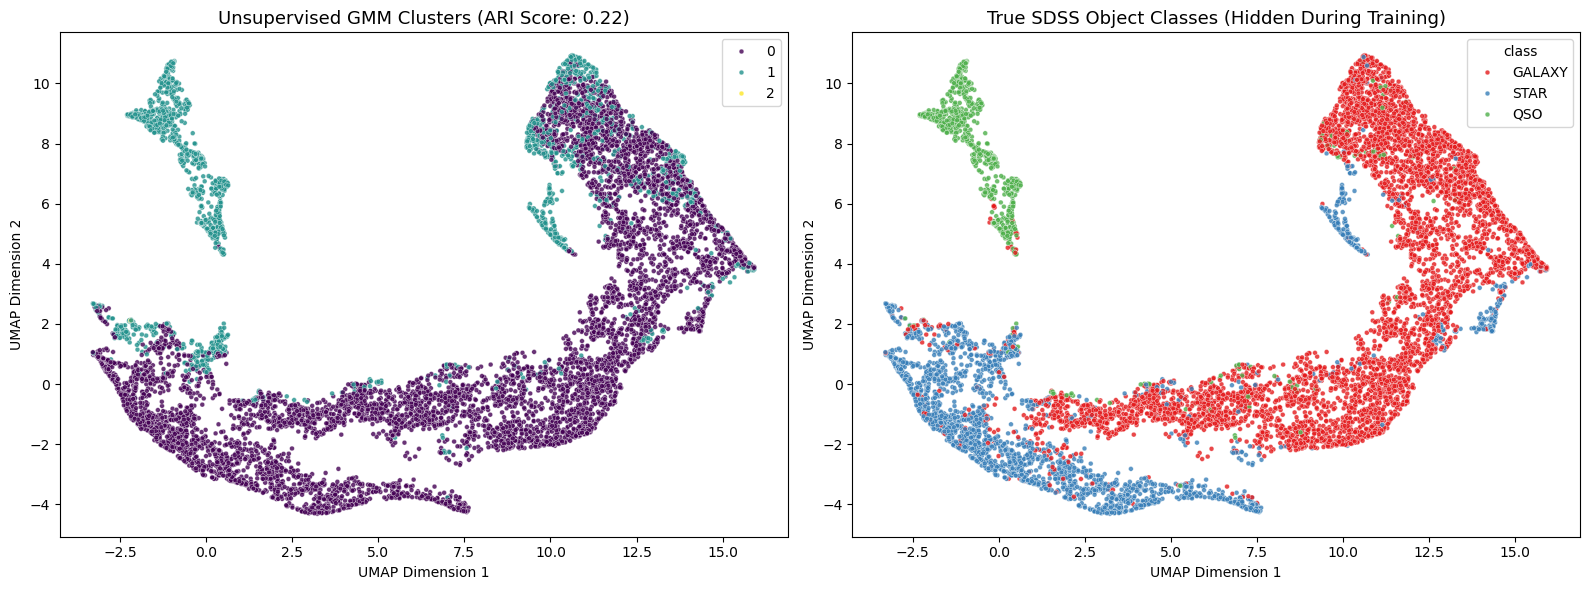

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left Plot: What your unsupervised model found
sns.scatterplot(
    x=embedding[:, 0], y=embedding[:, 1],
    hue=predicted_clusters, palette='viridis', s=12, alpha=0.8, ax=axes[0]
)
axes[0].set_title(f'Unsupervised GMM Clusters (ARI Score: {ari_score:.2f})', fontsize=13)
axes[0].set_xlabel('UMAP Dimension 1')
axes[0].set_ylabel('UMAP Dimension 2')

# Right Plot: Actual SDSS classifications (hidden during training)
sns.scatterplot(
    x=embedding[:, 0], y=embedding[:, 1],
    hue=true_labels, palette='Set1', s=12, alpha=0.8, ax=axes[1]
)
axes[1].set_title('True SDSS Object Classes (Hidden During Training)', fontsize=13)
axes[1].set_xlabel('UMAP Dimension 1')
axes[1].set_ylabel('UMAP Dimension 2')

plt.tight_layout()
plt.savefig('sdss_cluster_comparison.png', dpi=300)
plt.show()


Improved ARI Score (GMM on UMAP Manifold): 0.250


AttributeError: 'numpy.ndarray' object has no attribute 'xaxis'

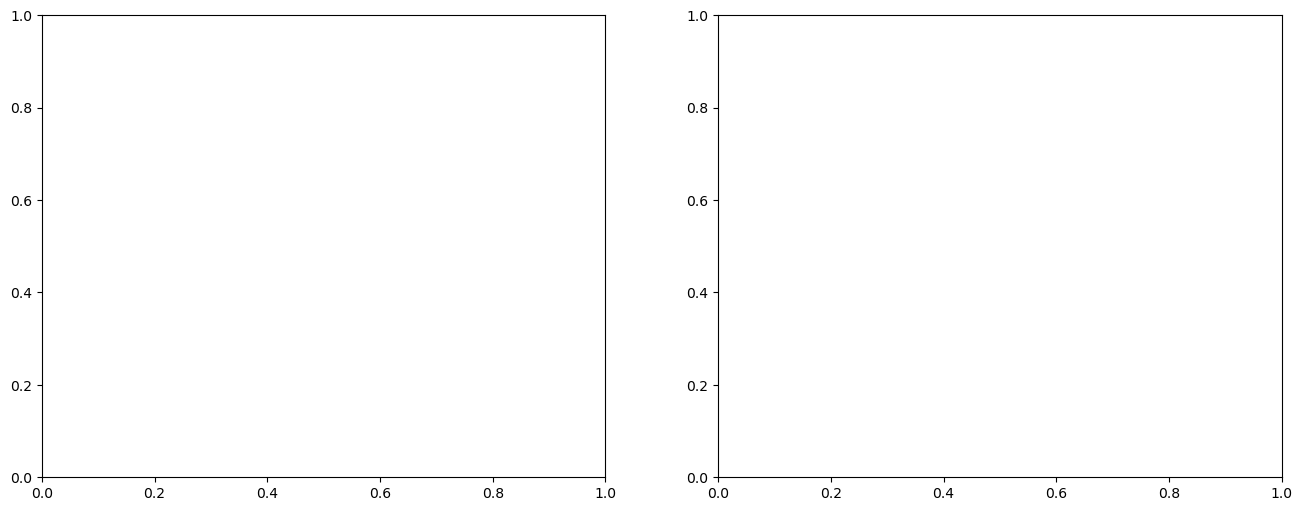

In [12]:
# Fit GMM directly on the non-linear 2D UMAP manifold instead of raw 5D space
gmm_umap = GaussianMixture(n_components=3, covariance_type='full', random_state=42)
predicted_clusters_umap = gmm_umap.fit_predict(embedding)

ari_umap = adjusted_rand_score(true_labels, predicted_clusters_umap)
print(f"Improved ARI Score (GMM on UMAP Manifold): {ari_umap:.3f}")

# Re-plot and overwrite the PNG with the improved separation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    x=embedding[:, 0], y=embedding[:, 1],
    hue=predicted_clusters_umap, palette='viridis', s=12, alpha=0.8, ax=axes
)
axes.set_title(f'GMM on UMAP Manifold (Improved ARI: {ari_umap:.2f})', fontsize=13)
axes.set_xlabel('UMAP Dimension 1')
axes.set_ylabel('UMAP Dimension 2')

sns.scatterplot(
    x=embedding[:, 0], y=embedding[:, 1],
    hue=true_labels, palette='Set1', s=12, alpha=0.8, ax=axes
)
axes.set_title('True SDSS Object Classes (Hidden During Training)', fontsize=13)
axes.set_xlabel('UMAP Dimension 1')
axes.set_ylabel('UMAP Dimension 2')

plt.tight_layout()
plt.savefig('sdss_cluster_comparison.png', dpi=300)
plt.show()


Improved ARI Score (GMM on UMAP Manifold): 0.250


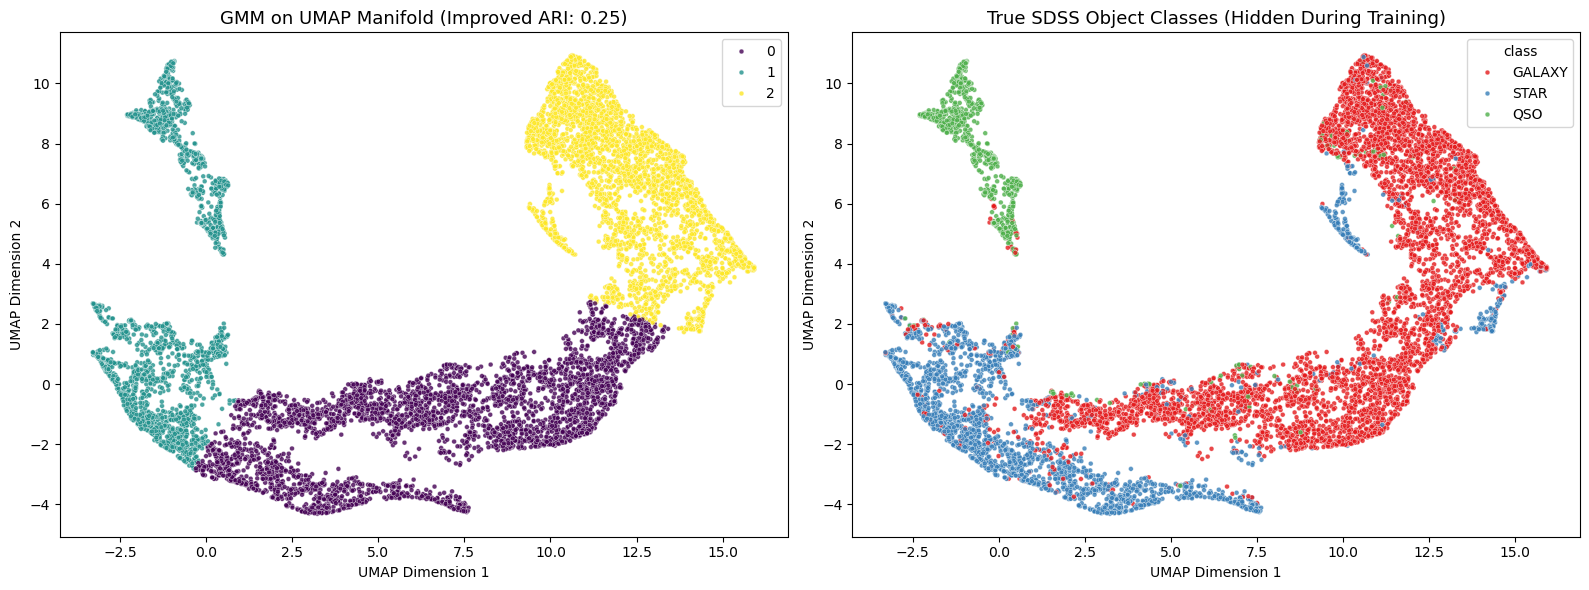

In [13]:
# Fit GMM directly on the non-linear 2D UMAP manifold instead of raw 5D space
gmm_umap = GaussianMixture(n_components=3, covariance_type='full', random_state=42)
predicted_clusters_umap = gmm_umap.fit_predict(embedding)

ari_umap = adjusted_rand_score(true_labels, predicted_clusters_umap)
print(f"Improved ARI Score (GMM on UMAP Manifold): {ari_umap:.3f}")

# Re-plot and overwrite the PNG with the improved separation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left Plot: axes[0]
sns.scatterplot(
    x=embedding[:, 0], y=embedding[:, 1],
    hue=predicted_clusters_umap, palette='viridis', s=12, alpha=0.8, ax=axes[0]
)
axes[0].set_title(f'GMM on UMAP Manifold (Improved ARI: {ari_umap:.2f})', fontsize=13)
axes[0].set_xlabel('UMAP Dimension 1')
axes[0].set_ylabel('UMAP Dimension 2')

# Right Plot: axes[1]
sns.scatterplot(
    x=embedding[:, 0], y=embedding[:, 1],
    hue=true_labels, palette='Set1', s=12, alpha=0.8, ax=axes[1]
)
axes[1].set_title('True SDSS Object Classes (Hidden During Training)', fontsize=13)
axes[1].set_xlabel('UMAP Dimension 1')
axes[1].set_ylabel('UMAP Dimension 2')

plt.tight_layout()
plt.savefig('sdss_cluster_comparison.png', dpi=300)
plt.show()


Density-Based Clustering (DBSCAN on UMAP) ARI Score: 0.295


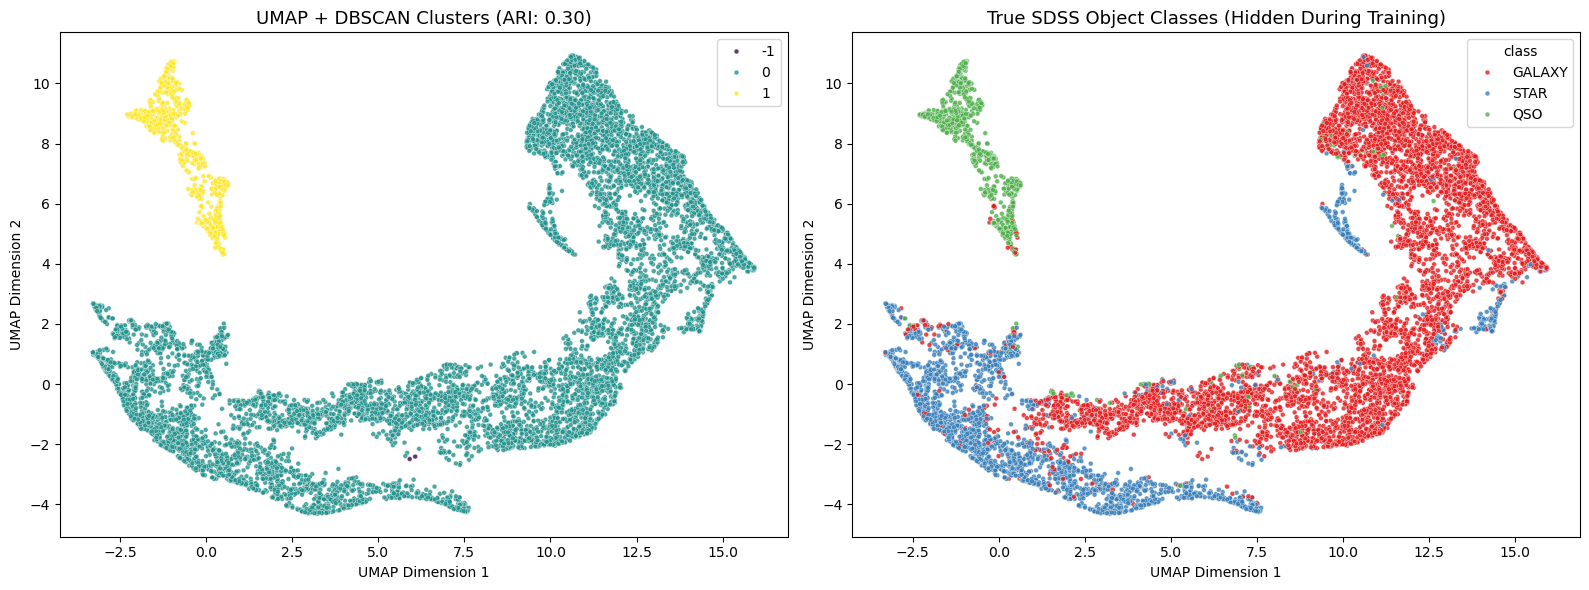

In [14]:
from sklearn.cluster import DBSCAN

# Density-based clustering follows curved manifolds instead of forcing ovals
dbscan = DBSCAN(eps=0.55, min_samples=25)
predicted_clusters_db = dbscan.fit_predict(embedding)

ari_db = adjusted_rand_score(true_labels, predicted_clusters_db)
print(f"Density-Based Clustering (DBSCAN on UMAP) ARI Score: {ari_db:.3f}")

# Plot final comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    x=embedding[:, 0], y=embedding[:, 1],
    hue=predicted_clusters_db, palette='viridis', s=12, alpha=0.8, ax=axes[0]
)
axes[0].set_title(f'UMAP + DBSCAN Clusters (ARI: {ari_db:.2f})', fontsize=13)
axes[0].set_xlabel('UMAP Dimension 1')
axes[0].set_ylabel('UMAP Dimension 2')

sns.scatterplot(
    x=embedding[:, 0], y=embedding[:, 1],
    hue=true_labels, palette='Set1', s=12, alpha=0.8, ax=axes[1]
)
axes[1].set_title('True SDSS Object Classes (Hidden During Training)', fontsize=13)
axes[1].set_xlabel('UMAP Dimension 1')
axes[1].set_ylabel('UMAP Dimension 2')

plt.tight_layout()
plt.savefig('sdss_cluster_comparison.png', dpi=300)
plt.show()
